In [ ]:
'''
Smoothing family
    moving average for forecast
    exponential smoothing family
        ses - single exponential smoothening
            data with no clear trend and seasonality - just random numbers
            this can be called weighted rolling 
            higher alpha = higher weight to recency
            equation (can replact y with level, i,e L): y'(t+1)=alpha*(yt)+(1-alpha)*y(t-1)
        des [HOLT'S METHOD] - double exponential smoothening
            data with trend but no seasonality
            2 primary Components
                trend (slope) - T
                level - baseline recent data - L
            equations: l(t)=alpha*l(t)+(1-alpha)*(l(t-1)+T(t-1))
                    T(t)=beta*(l(t)-l(t-1))+(1-beta)*T(t-1)
                    Forecasts for m periods forward: Y(t+m)=L(t+m)+m*(T(t))

        tes - triple exponential smoothening
            3 Components
                trend (slope) - T
                level - baseline recent data - L
                Seasonality - S
            equations:
                L(t) = alpha*(y(t)-S(t-p))+(1-alpha)*(L(t-1)+T(t-1))
                T(t) = beta*(L(t)-L(t-1))+(1-beta)*T(t-1)
                S(t) = gamma*(y(t)-L(t))+ (1-gamma)*S(t-p)

                Forecasts for m periods forward: L(t)+S(t+m-p)+m*T(t)
                where p is season window


Thumb rule to choose alpha: 1/(2*p)                
                
Stationarity in time series - need stationary series for AR family models
    Test it by using 

'''

In [11]:
import pandas as pd 
import numpy as np 
from sklearn.metrics import mean_absolute_percentage_error,mean_absolute_error,root_mean_squared_error
import matplotlib.pyplot as plt
import statsmodels.api as sm


# pre processing

In [2]:
df=pd.read_csv(r'C:\Users\Mayank Bhatia\Documents\GitHub\DSML\16_ml_unsupervised_and_recsys\16.3_time_seties_analysis_2\mobilesales.csv')
df['DATE']=pd.to_datetime(df['DATE'], format='%d-%m-%Y')
df.index=df['DATE']

In [3]:
df['Sales_2']=df['Sales'].interpolate(method='linear')
df['Sales_3']=df['Sales_2'].clip(upper=np.quantile(df['Sales_2'],0.98),lower=np.quantile(df['Sales_2'],0.2))

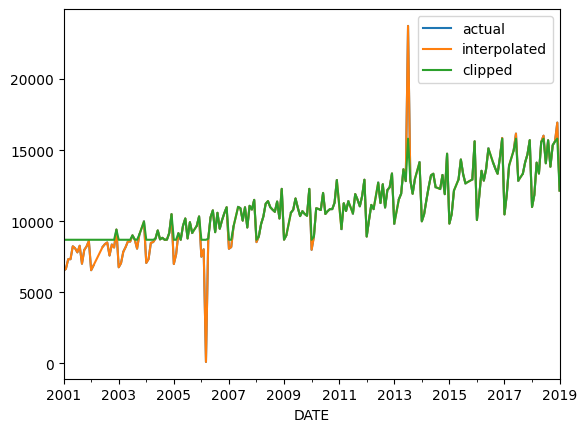

In [4]:
df['Sales'].plot(label='actual')
df['Sales_2'].plot(label='interpolated')
df['Sales_3'].plot(label='clipped')

plt.legend()

In [5]:
df_train=df[:-12]
df_test=df[-12:]

# Single exponential smoothening

In [6]:
model=sm.tsa.ExponentialSmoothing(df_train['Sales_3'],seasonal=None,trend=None).fit(smoothing_level=1/(12*2))

c:\Users\Mayank Bhatia\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


<Axes: xlabel='DATE'>

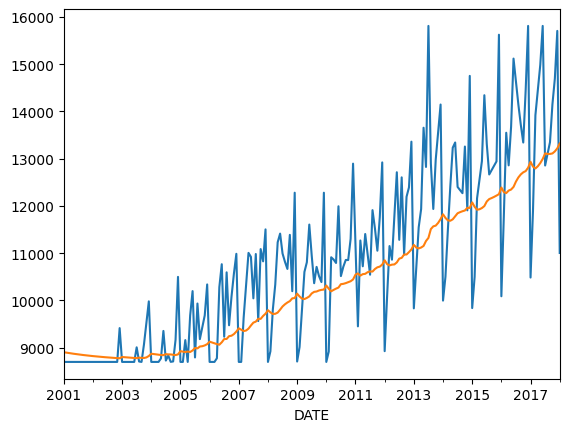

In [7]:

df_train['Sales_3'].plot(label="Actual")
model.fittedvalues.plot(label="fitted")


In [8]:
df_test['pred_ses']=model.forecast(steps=12)

In [14]:
df_test

,DATE,Sales,Sales_2,Sales_3,pred_ses
DATE,,,,,
2018-02-01,2018-02-01,11852.0,11852.0,11852.0,13225.65713
2018-03-01,2018-03-01,14123.0,14123.0,14123.0,13225.65713
2018-04-01,2018-04-01,13360.0,13360.0,13360.0,13225.65713
2018-05-01,2018-05-01,15576.0,15576.0,15576.0,13225.65713
2018-06-01,2018-06-01,16021.0,16021.0,15809.4,13225.65713
2018-07-01,2018-07-01,14080.0,14080.0,14080.0,13225.65713
2018-08-01,2018-08-01,15697.0,15697.0,15697.0,13225.65713
2018-09-01,2018-09-01,13838.0,13838.0,13838.0,13225.65713
2018-10-01,2018-10-01,15351.0,15351.0,15351.0,13225.65713


In [17]:
print("rmse is ",root_mean_squared_error(df_test['Sales_3'],df_test['pred_ses']))
print("mape is ",mean_absolute_percentage_error(df_test['Sales_3'],df_test['pred_ses']))
print("mae is ",mean_absolute_error(df_test['Sales_3'],df_test['pred_ses']))

rmse is  1829.3860554915111
mape is  0.10906015916137418
mae is  1620.1285799563145


# Double exponential smoothening

In [20]:
model=sm.tsa.ExponentialSmoothing(df_train['Sales_3'],seasonal=None,trend='add').fit(smoothing_level=1/(12*2))

c:\Users\Mayank Bhatia\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


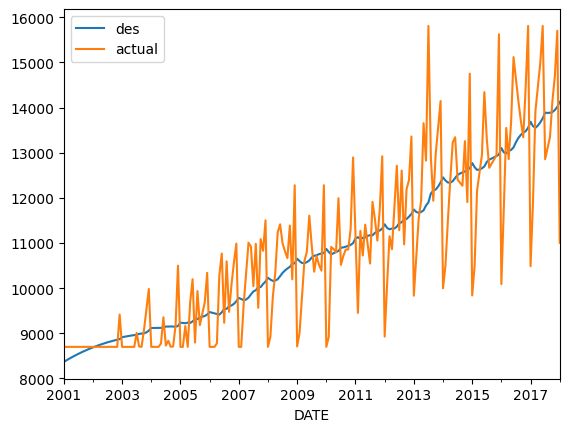

In [23]:
model.fittedvalues.plot(label='des')
df_train['Sales_3'].plot(label='actual')
plt.legend()

In [21]:
df_test['pred_des']=model.forecast(12)

In [24]:
print("rmse is ",root_mean_squared_error(df_test['Sales_3'],df_test['pred_des']))
print("mape is ",mean_absolute_percentage_error(df_test['Sales_3'],df_test['pred_des']))
print("mae is ",mean_absolute_error(df_test['Sales_3'],df_test['pred_des']))

rmse is  1359.3721384673013
mape is  0.08309875773485732
mae is  1171.4603527493323


# Triple exponential smoothening

In [26]:
model=sm.tsa.ExponentialSmoothing(df_train['Sales_3'],trend='add',seasonal='add').fit(smoothing_level=1/(12*2))

c:\Users\Mayank Bhatia\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


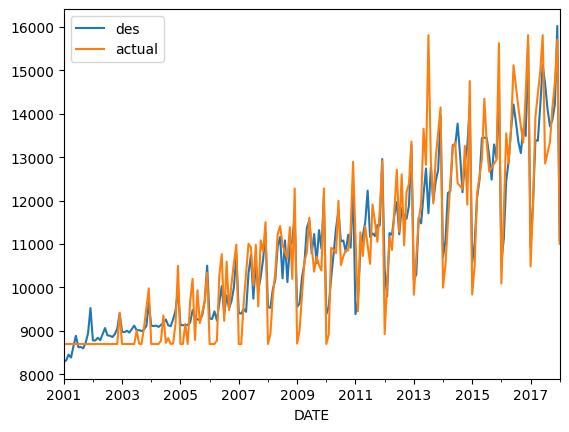

In [27]:
model.fittedvalues.plot(label='des')
df_train['Sales_3'].plot(label='actual')
plt.legend()

In [28]:
df_test['pred_tes']=model.forecast(12)

In [29]:
print("rmse is ",root_mean_squared_error(df_test['Sales_3'],df_test['pred_tes']))
print("mape is ",mean_absolute_percentage_error(df_test['Sales_3'],df_test['pred_tes']))
print("mae is ",mean_absolute_error(df_test['Sales_3'],df_test['pred_tes']))

rmse is  760.990232713105
mape is  0.041463417203311696
mae is  605.3547176719854


# Stationarity test - adfuller test

In [ ]:
sm.tsa.stattools.adfuller(df['Sales_3'])[1]

# for being stationary, p_value has to be less than alpha(0.05 in this case). hence not stationary

np.float64(0.9948696615760129)